In [1]:
%matplotlib widget
import numpy as np
import tomllib
from pathlib import Path

from thesis_code.plotting import plot_performance, plot_gradients, plot_weight_matrices, InteractiveSpikePlot

In [2]:
work_dir = Path.cwd()
print(work_dir)
with open(work_dir / "config.toml", 'rb') as cfg_file:
    cfg = tomllib.load(cfg_file)

n_trials = cfg["training"]["n_trials"]

def load_recording(data_name: str, key: str, skip_is: list[int] = []) -> np.ndarray:
    data = []
    for i in range(n_trials):
        if i not in skip_is:
            with np.load(work_dir / f"seed_{i}" / "data_net" / f"{data_name}.npz") as d:
                data.append(d[key])
    return np.array(data)

def get_data(data_name: str, skip_is: list[int] = []) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_0" / "data_net" / f"{data_name}.npz") as d:
        keys = list(d.keys())
    return {key: load_recording(data_name, key, skip_is) for key in keys}

def get_data_seed(data_name: str, seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / "data_net" / f"{data_name}.npz") as d:
        return {key: d[key] for key in list(d.keys())}

def filter_seeds(data: np.ndarray, seeds: list[int]) -> np.ndarray:
    return np.take(data, seeds, axis=0)

def unpack_bits(data: dict[np.ndarray], key: str, suffix: str = "-n_cols") -> np.ndarray:
    unpack_key = key + suffix
    if unpack_key in data.keys():
        return np.unpackbits(data[key], axis=-1, count=int(data[unpack_key])).astype(bool)
    return data[key]

c:\Users\emiel\Documents\Study\Thesis\Thesis-Code\important_outputs\2026-10-16_13-32-36-test_no_daleslaw_no_refractory_period


In [3]:
skip_is = []

[[False False False False False False False False False False False False
  False False False False False False False False]
 [False False False False False  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True]
 [False False False False False False False False False False False False
  False False False False False False False False]
 [False False False False False False False False False False False False
  False False False False False False False False]
 [False False False False False False False False False False False False
  False False False False False False False False]]


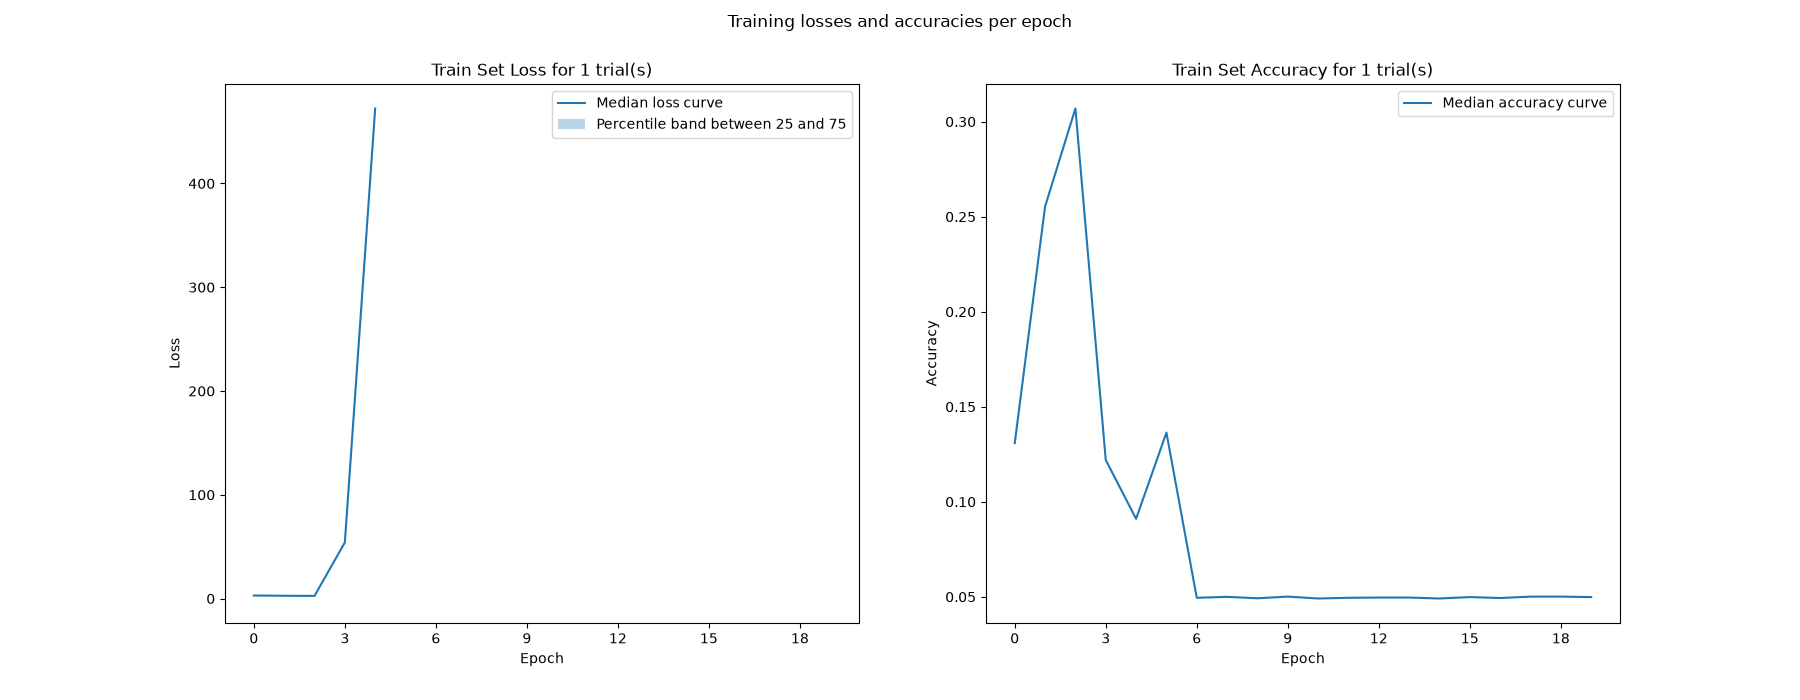

In [ ]:
plot_seeds = [4]
perf_data = get_data("performance", skip_is)
print(np.isnan(perf_data["loss"]))
plot_performance(filter_seeds(perf_data["loss"], plot_seeds), filter_seeds(perf_data["acc"], plot_seeds))

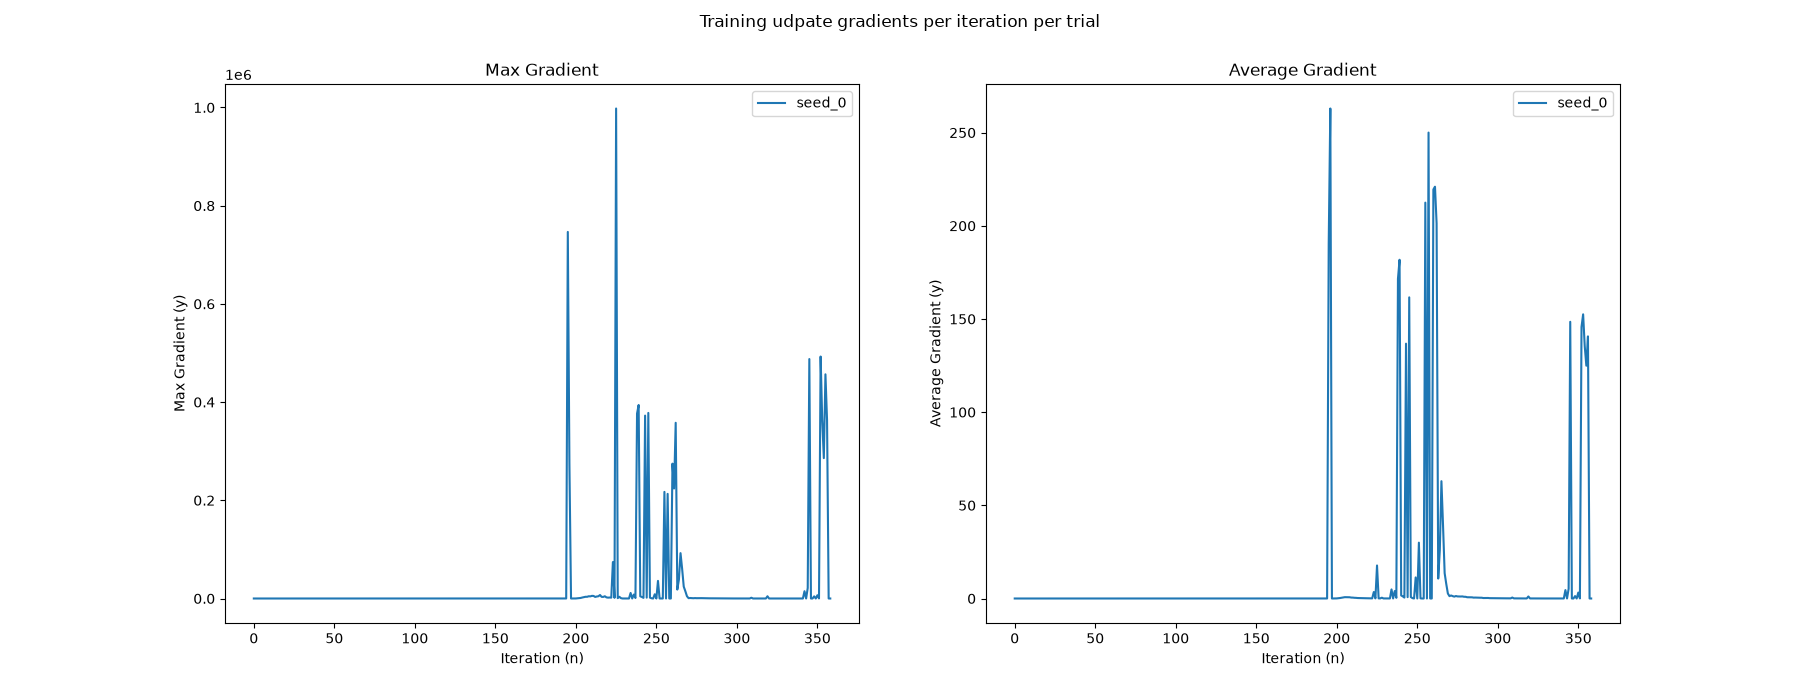

In [ ]:
plot_seeds = [4]
grad_data = get_data("gradients", skip_is)
plot_gradients(filter_seeds(grad_data["max_grad"], plot_seeds), filter_seeds(grad_data["avg_grad"], plot_seeds))

In [ ]:
print(get_data_seed("weights", 1).keys())
for key, data in get_data_seed("weights", 1).items():
    plot_weight_matrices(data, name=key)

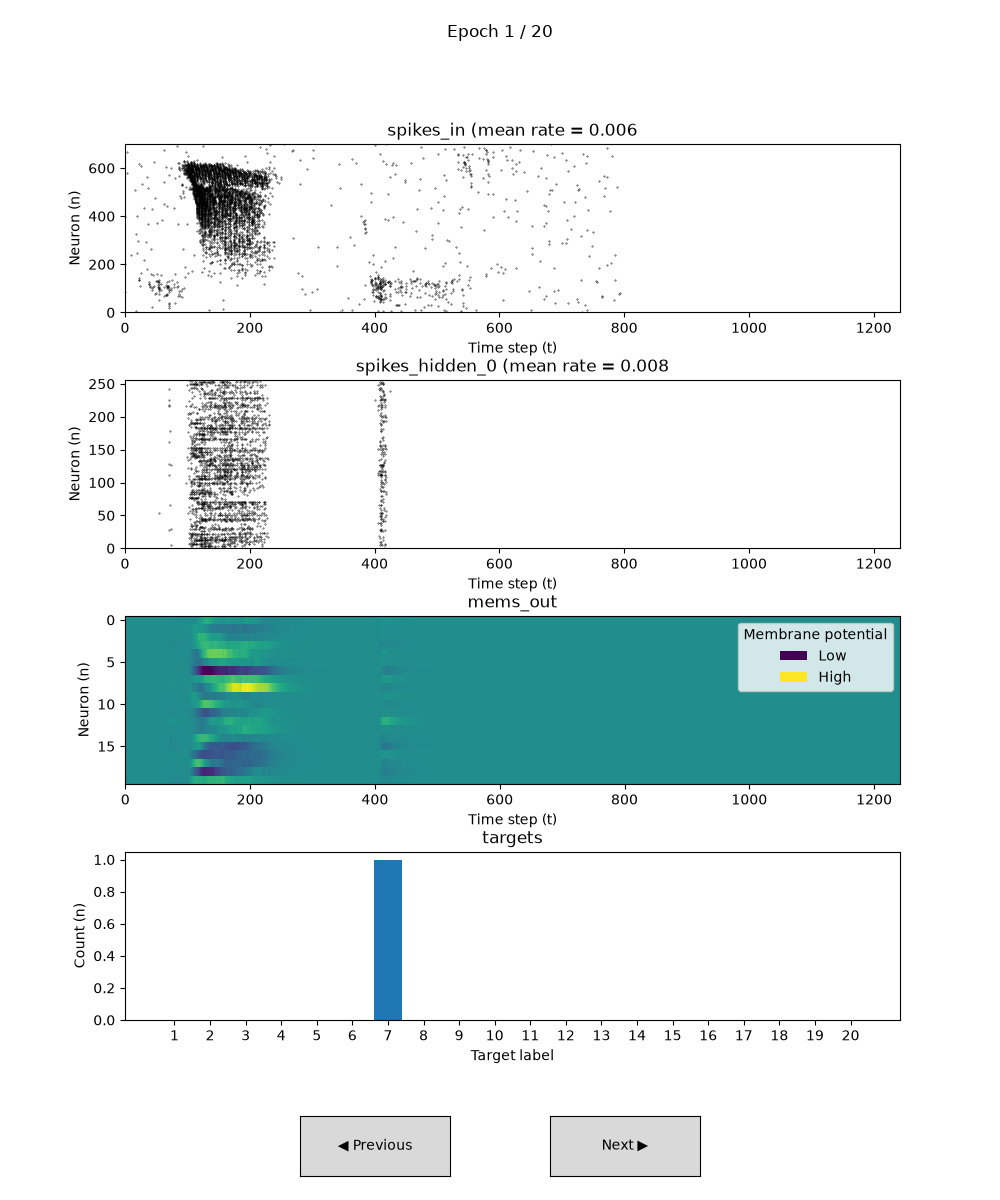

RuntimeError: Another Axes already grabs mouse input

In [ ]:
data = get_data_seed("spikes", seed=4)
layer_spikes = {
    k: unpack_bits(data, k)
    for k in ["spikes_in", "spikes_hidden_0", "mems_out", "targets"]
    if not k.endswith(("-lengths", "-n_cols"))
}

isp = InteractiveSpikePlot(layer_spikes, range(1, 21))
isp.draw()